# PLSA Retrieval Validation and Query Study

This experiment evaluates how effectively PLSA retrieves relevant documents compared with TF-IDF and LSI. We divide the dataset into training, validation, and test sets. All three methods use the same vocabulary and candidate documents to ensure a fair comparison.

We use a fixed set of 18 queries across six categories, with three types of queries for each category: direct keywords, paraphrases, and related domain terms. This helps us examine how retrieval performance changes when queries use different wording.

The validation set is used to select the number of latent topics (K) and tune query-likelihood settings, such as background smoothing. After selecting these settings, we evaluate the models on the held-out test set to compare their retrieval performance using metrics such as Precision@10, MAP@10, and MRR.

We also examine query vocabulary coverage to determine how many query terms are present in the training vocabulary and whether missing terms may affect retrieval. Additionally, we perform runtime and memory profiling to measure the computational resources required for PLSA training and inference. This helps us understand not only how well PLSA retrieves documents, but also how efficiently it operates.

In [1]:
# %pip -q install numpy scipy scikit-learn pandas matplotlib

## 1. Imports and reproducibility

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)


## 2. Load a six-category subset of 20 Newsgroups

We deliberately restrict the corpus to six reasonably distinct categories. This changes the documents used to train PLSA, unlike merely merging the original labels after training. The categories remain the dataset's original labels and no labels are passed to PLSA's EM algorithm.

In [3]:
SELECTED_CATEGORIES = [
    "comp.graphics",
    "misc.forsale",
    "rec.sport.baseball",
    "sci.med",
    "sci.space",
    "talk.politics.guns",
]

dataset = fetch_20newsgroups(
    subset="all",
    categories=SELECTED_CATEGORIES,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=SEED
)
documents = np.array(dataset.data, dtype=object)
labels = np.asarray(dataset.target)
target_names = list(dataset.target_names)

print("Selected categories:", len(target_names))
print("Total documents:", len(documents))
for i, name in enumerate(target_names):
    print(f"{i:2d} | {name:25s} | {(labels == i).sum():5d} documents")

print("\nNote: category names are evaluation labels only; PLSA is trained without using them.")

Selected categories: 6
Total documents: 5829
 0 | comp.graphics             |   973 documents
 1 | misc.forsale              |   975 documents
 2 | rec.sport.baseball        |   994 documents
 3 | sci.med                   |   990 documents
 4 | sci.space                 |   987 documents
 5 | talk.politics.guns        |   910 documents

Note: category names are evaluation labels only; PLSA is trained without using them.


### Why use a subset?
We selected six categories with more distinct topics from the original dataset to check whether PLSA can identify clearer topics and retrieve relevant documents more effectively. This is a diagnostic experiment, not proof that six is the best number of topics. We will also test different values of K (the number of latent topics learned by PLSA), since the number of dataset categories and the number of learned topics can be different.

In [4]:
# Resource profiling utilities
import os
import time
import threading
import psutil
import pandas as pd

_process = psutil.Process(os.getpid())

def profile_resources(function, *args, **kwargs):
    """
    Measure wall-clock runtime and process RSS memory while a function runs.
    Returns: function result and a dictionary of measurements.
    """
    memory_samples = [_process.memory_info().rss / (1024 ** 2)]
    stop_sampling = threading.Event()

    def sample_memory():
        while not stop_sampling.is_set():
            try:
                memory_samples.append(
                    _process.memory_info().rss / (1024 ** 2)
                )
            except psutil.Error:
                pass
            stop_sampling.wait(0.05)

    memory_before = _process.memory_info().rss / (1024 ** 2)
    sampler = threading.Thread(target=sample_memory, daemon=True)

    start = time.perf_counter()
    sampler.start()

    try:
        result = function(*args, **kwargs)
    finally:
        elapsed = time.perf_counter() - start
        stop_sampling.set()
        sampler.join()
        memory_after = _process.memory_info().rss / (1024 ** 2)

    measurements = {
        "runtime_seconds": round(elapsed, 3),
        "memory_before_MB": round(memory_before, 2),
        "memory_after_MB": round(memory_after, 2),
        "peak_process_memory_MB": round(max(memory_samples), 2),
        "peak_increase_from_start_MB": round(
            max(memory_samples) - memory_before, 2
        ),
    }

    return result, measurements

print("Resource profiling utilities are ready.")

Resource profiling utilities are ready.


## 3. Train/test split and preprocessing

Text preprocessing cleans documents by removing unnecessary words and punctuation and converting words to their base forms. The cleaned text is then converted into numerical word-count matrices for PLSA.

In [6]:
import spacy
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer


docs_train, docs_temp, y_train, y_temp = train_test_split(
    documents, labels, test_size=0.40, random_state=SEED, stratify=labels
)
docs_val, docs_test, y_val, y_test = train_test_split(
    docs_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

def preprocess_texts(texts):
    result = []
    for doc in nlp.pipe(texts, batch_size=256):
        tokens = []
        for token in doc:
            if token.is_space or token.is_punct or token.like_num or not token.is_alpha or token.is_stop:
                continue
            lemma = token.lemma_.lower().strip()
            if len(lemma) >= 2:
                tokens.append(lemma)
        result.append(" ".join(tokens))
    return result

docs_train_processed = preprocess_texts(docs_train)
docs_val_processed = preprocess_texts(docs_val)
docs_test_processed = preprocess_texts(docs_test)
count_vectorizer = CountVectorizer(
    lowercase=False, tokenizer=str.split, token_pattern=None,
    max_features=3000, min_df=3, max_df=0.90, dtype=np.float64
)
X_train = count_vectorizer.fit_transform(docs_train_processed)
X_val = count_vectorizer.transform(docs_val_processed)
X_test = count_vectorizer.transform(docs_test_processed)
vocabulary = count_vectorizer.get_feature_names_out()
print("Documents train/validation/test:", len(docs_train), len(docs_val), len(docs_test))
print("Count matrices:", X_train.shape, X_val.shape, X_test.shape)
print("Empty docs train/validation/test:",
      sum(not x.strip() for x in docs_train_processed),
      sum(not x.strip() for x in docs_val_processed),
      sum(not x.strip() for x in docs_test_processed))


Documents train/validation/test: 3497 1166 1166
Count matrices: (3497, 3000) (1166, 3000) (1166, 3000)
Empty docs train/validation/test: 97 42 33



## 4. PLSA Model and EM Algorithm

For document \(d\), word \(w\), and latent topic \(z\):

$$
P(w \mid d) = \sum_{z=1}^{K} P(w \mid z)P(z \mid d)
$$

- $\theta_{d,z} = P(z \mid d)$: document-topic distribution.
- $\phi_{z,w} = P(w \mid z)$: topic-word distribution.
- Each row of $\theta$ and $\phi$ sums to one.

**E-step:** Calculate the probability that topic \(z\) generated word \(w\) in document \(d\).

$$
P(z\mid d,w)=
\frac{P(z\mid d)P(w\mid z)}
{\sum_{z'=1}^{K}P(z'\mid d)P(w\mid z')}
$$

**M-step:** Update the document-topic and topic-word distributions using the expected word counts. Repeat the E-step and M-step until the log-likelihood stops improving.


In [7]:
class PLSA:
    """PLSA trained directly with NumPy EM and sparse input counts."""

    def __init__(self, n_topics=5, max_iter=100, tol=1e-4,
                 random_state=42, beta=1.0):
        if n_topics < 1:
            raise ValueError("n_topics must be positive")
        if not (0 < beta):
            raise ValueError("beta must be positive")
        self.n_topics = n_topics
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.beta = beta
        self.log_likelihoods = []

    @staticmethod
    def _normalize(a, axis):
        denom = np.maximum(a.sum(axis=axis, keepdims=True), 1e-15)
        return a / denom

    @staticmethod
    def _observations(X):
        X = csr_matrix(X, dtype=np.float64)
        X.eliminate_zeros()
        X.sum_duplicates()
        docs, words, counts = [], [], []
        for d in range(X.shape[0]):
            start, end = X.indptr[d], X.indptr[d + 1]
            if end > start:
                docs.append(np.full(end-start, d, dtype=np.int64))
                words.append(X.indices[start:end].astype(np.int64))
                counts.append(X.data[start:end].astype(np.float64))
        if not docs:
            raise ValueError("Input has no observed word counts.")
        return X, np.concatenate(docs), np.concatenate(words), np.concatenate(counts)

    def fit(self, X):
        X, doc_ids, word_ids, counts = self._observations(X)
        D, V = X.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state)

        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)
        phi = self._normalize(rng.random((K, V)) + 1e-3, axis=1)
        self.log_likelihoods = []

        for iteration in range(self.max_iter):

            unnorm = theta[doc_ids].T * phi[:, word_ids]
            if self.beta != 1.0:
                unnorm = np.maximum(unnorm, 1e-15) ** self.beta
            posterior = unnorm / np.maximum(
                unnorm.sum(axis=0, keepdims=True), 1e-15
            )


            weighted = posterior * counts[None, :]
            topic_word = np.zeros((K, V), dtype=np.float64)
            doc_topic = np.zeros((D, K), dtype=np.float64)

            for k in range(K):
                np.add.at(topic_word[k], word_ids, weighted[k])
                np.add.at(doc_topic[:, k], doc_ids, weighted[k])

            phi = self._normalize(topic_word + 1e-12, axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)


            p_observed = np.sum(theta[doc_ids] * phi[:, word_ids].T, axis=1)
            ll = float(np.sum(counts * np.log(np.maximum(p_observed, 1e-15))))
            self.log_likelihoods.append(ll)

            if iteration > 0:
                improvement = ll - previous_ll
                if self.beta == 1.0 and improvement < -1e-7:
                    print("Warning: likelihood decreased slightly; check numerical behavior.")
                if abs(improvement) <= self.tol * (1 + abs(previous_ll)):
                    break
            previous_ll = ll

        self.theta_ = theta
        self.phi_ = phi
        self.n_features_in_ = V
        self.n_iter_ = len(self.log_likelihoods)
        return self

    def transform(self):
        """Document-topic probabilities for the documents used in fit()."""
        return self.theta_

    def fold_in(self, X_new, max_iter=100):
        """Infer P(z|d_new) with learned P(w|z) fixed."""
        X_new = csr_matrix(X_new, dtype=np.float64)
        if X_new.shape[1] != self.n_features_in_:
            raise ValueError("New data must use the same fitted vocabulary.")
        D, V = X_new.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state + 1000)
        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)

        for _ in range(max_iter):
            doc_topic = np.zeros((D, K), dtype=np.float64)
            for d in range(D):
                start, end = X_new.indptr[d], X_new.indptr[d + 1]
                words = X_new.indices[start:end]
                counts = X_new.data[start:end]
                if len(words) == 0:
                    continue
                unnorm = theta[d, :, None] * self.phi_[:, words]
                if self.beta != 1.0:
                    unnorm = np.maximum(unnorm, 1e-15) ** self.beta
                posterior = unnorm / np.maximum(
                    unnorm.sum(axis=0, keepdims=True), 1e-15
                )
                doc_topic[d] = (posterior * counts[None, :]).sum(axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)
        return theta

    def top_words(self, vocabulary, n=10):
        result = {}
        for k, dist in enumerate(self.phi_):
            ids = np.argsort(dist)[::-1][:n]
            result[k] = [(vocabulary[i], float(dist[i])) for i in ids]
        return result


## 5. Multiple random restarts

EM can produce different results depending on its starting values, so we run the model multiple times and select the one with the highest training log-likelihood. However, we evaluate its retrieval performance separately using test data.

Although our dataset has six categories, we do not have to use K=6. PLSA may combine similar categories or divide one category into multiple topics. We start with K=6 and test other values to find how the number of topics affects performance.

In [8]:
def train_plsa_restarts(X, n_topics=5, n_restarts=5,
                        max_iter=100, tol=1e-4, base_seed=42):
    runs = []
    for r in range(n_restarts):
        model = PLSA(
            n_topics=n_topics, max_iter=max_iter, tol=tol,
            random_state=base_seed + r, beta=1.0
        ).fit(X)
        final_ll = model.log_likelihoods[-1]
        runs.append((model, final_ll))
        print(f"Restart {r+1}: final training log-likelihood={final_ll:.3f}, "
              f"iterations={model.n_iter_}")
    best_model, best_ll = max(runs, key=lambda item: item[1])
    print("Selected best training likelihood:", round(best_ll, 3))
    return best_model, runs

K = 6
best_plsa, restart_runs = train_plsa_restarts(
    X_train, n_topics=K, n_restarts=5, max_iter=100
)
theta_train = best_plsa.transform()
theta_test = best_plsa.fold_in(X_test, max_iter=100)
print("theta_train:", theta_train.shape)
print("theta_test:", theta_test.shape)


Restart 1: final training log-likelihood=-1389493.194, iterations=44
Restart 2: final training log-likelihood=-1380331.453, iterations=52
Restart 3: final training log-likelihood=-1384610.260, iterations=57
Restart 4: final training log-likelihood=-1381797.269, iterations=45
Restart 5: final training log-likelihood=-1386646.077, iterations=46
Selected best training likelihood: -1380331.453
theta_train: (3497, 6)
theta_test: (1166, 6)


## 6. PLSA Training: Runtime and Memory Profiling

We train PLSA with 20 topics and measure the resources required, including training time and memory usage. We also record the number of iterations completed and the final training log-likelihood to assess the model's training performance.

In [9]:
def fit_plsa_for_profiling():
    model = PLSA(
        n_topics=20,
        max_iter=100,
        tol=1e-4,
        random_state=SEED + 2026,
        beta=1.0
    )
    return model.fit(X_train)

profiled_plsa, training_measurements = profile_resources(
    fit_plsa_for_profiling
)

training_measurements["operation"] = "PLSA training"
training_measurements["K"] = profiled_plsa.n_topics
training_measurements["iterations_completed"] = profiled_plsa.n_iter_
training_measurements["final_training_log_likelihood"] = (
    profiled_plsa.log_likelihoods[-1]
)

training_resources_df = pd.DataFrame([training_measurements])

display(training_resources_df)

,runtime_seconds,memory_before_MB,memory_after_MB,peak_process_memory_MB,peak_increase_from_start_MB,operation,K,iterations_completed,final_training_log_likelihood
0,17.8,114.89,120.33,240.26,125.37,PLSA training,20,73,-1.314684e+06


## 7. Inspect topics and convergence

Topic IDs are arbitrary: topic 0 is not inherently sports or politics. Interpret each topic by its highest-probability words, and use category-level averages only as a diagnostic.


Topic 0:
people (0.014), think (0.013), gun (0.012), like (0.010), know (0.010), right (0.008), time (0.008), thing (0.007), go (0.006), say (0.006), want (0.006), come (0.005)

Topic 1:
game (0.026), year (0.018), team (0.013), run (0.012), player (0.011), hit (0.011), good (0.011), win (0.011), play (0.009), think (0.008), time (0.008), pitch (0.007)

Topic 2:
image (0.020), file (0.014), program (0.010), software (0.010), format (0.009), bit (0.008), use (0.008), system (0.008), available (0.007), graphic (0.007), color (0.007), jpeg (0.007)

Topic 3:
new (0.017), price (0.012), good (0.012), offer (0.012), sale (0.012), sell (0.011), copy (0.011), book (0.010), thank (0.009), include (0.009), condition (0.008), mail (0.008)

Topic 4:
patient (0.010), disease (0.009), medical (0.009), cause (0.008), doctor (0.008), study (0.008), drug (0.007), cancer (0.007), effect (0.006), know (0.006), problem (0.006), health (0.006)

Topic 5:
space (0.021), launch (0.010), nasa (0.007), center 

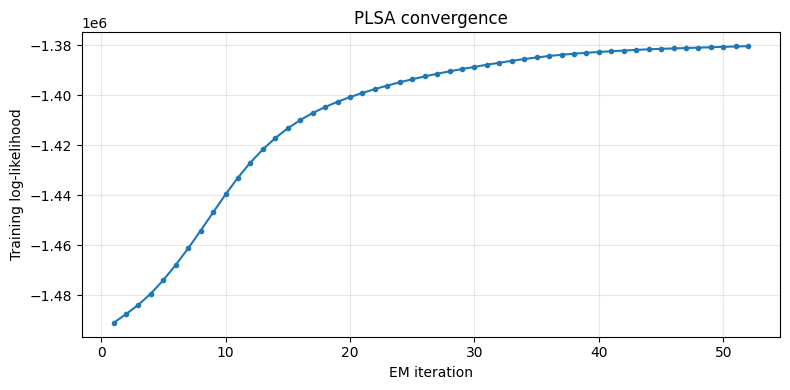

In [10]:
for topic_id, words in best_plsa.top_words(vocabulary, n=12).items():
    print(f"\nTopic {topic_id}:")
    print(", ".join(f"{word} ({prob:.3f})" for word, prob in words))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(best_plsa.log_likelihoods)+1),
         best_plsa.log_likelihoods, marker="o", markersize=3)
plt.xlabel("EM iteration")
plt.ylabel("Training log-likelihood")
plt.title("PLSA convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Controlled topic-boundary experiment

We create artificial documents by mixing words from baseball and gun politics documents. We then use PLSA to estimate the topic proportions and compare them with the original word proportions.

However, the word proportions may not exactly match the estimated topic probabilities because topics can overlap or represent only part of a category. We identify the baseball-related and politics-related topics by checking which topics are most common in documents from each category.

In [11]:
sports_class = target_names.index("rec.sport.baseball")
politics_class = target_names.index("talk.politics.guns")

class_topic_means = np.vstack([
    theta_train[y_train == c].mean(axis=0)
    for c in range(len(target_names))
])
sports_topic = int(class_topic_means[sports_class].argmax())
politics_topic = int(class_topic_means[politics_class].argmax())

print("Sports-associated topic:", sports_topic)
print("Politics-associated topic:", politics_topic)
if sports_topic == politics_topic:
    print("Warning: both categories map to the same dominant topic; interpret estimates cautiously.")

def sample_token_ids(row):
    row = csr_matrix(row)
    return np.repeat(row.indices, row.data.astype(int))

def make_mixed_document(X_source, y_source, class_a, class_b,
                        ratio_a, rng, n_tokens=300):

    a_candidates = np.where((y_source == class_a) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]
    b_candidates = np.where((y_source == class_b) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]

    da = X_source[a_candidates[rng.integers(len(a_candidates))]]
    db = X_source[b_candidates[rng.integers(len(b_candidates))]]
    tokens_a = sample_token_ids(da)
    tokens_b = sample_token_ids(db)
    if len(tokens_a) == 0 or len(tokens_b) == 0:
        raise ValueError("A sampled source document had no in-vocabulary tokens.")
    n_a = int(round(n_tokens * ratio_a))
    n_b = n_tokens - n_a
    tokens = np.concatenate([
        rng.choice(tokens_a, size=n_a, replace=True),
        rng.choice(tokens_b, size=n_b, replace=True)
    ])
    counts = np.bincount(tokens, minlength=X_source.shape[1]).astype(float)
    return csr_matrix(counts.reshape(1, -1))

boundary_rng = np.random.default_rng(SEED + 77)
ratios = [0.9, 0.7, 0.5, 0.3, 0.1]
boundary_rows = []

for ratio in ratios:
    for replicate in range(20):
        mixed_X = make_mixed_document(
            X_train, y_train, sports_class, politics_class,
            ratio, boundary_rng, n_tokens=300
        )
        estimate = best_plsa.fold_in(mixed_X, max_iter=100)[0]
        boundary_rows.append({
            "source_category_a": "rec.sport.baseball",
            "source_category_b": "talk.politics.guns",
            "actual_sports_word_ratio": ratio,
            "actual_politics_word_ratio": 1-ratio,
            "estimated_sports_topic": estimate[sports_topic],
            "estimated_politics_topic": estimate[politics_topic],
            "replicate": replicate
        })

boundary_df = pd.DataFrame(boundary_rows)
boundary_summary = boundary_df.groupby("actual_sports_word_ratio").agg(
    estimated_sports_mean=("estimated_sports_topic", "mean"),
    estimated_sports_std=("estimated_sports_topic", "std"),
    estimated_politics_mean=("estimated_politics_topic", "mean"),
    estimated_politics_std=("estimated_politics_topic", "std")
).reset_index()
display(boundary_summary)

Sports-associated topic: 1
Politics-associated topic: 0


,actual_sports_word_ratio,estimated_sports_mean,estimated_sports_std,estimated_politics_mean,estimated_politics_std
0,0.1,0.080113,0.069339,0.800148,0.157351
1,0.3,0.234753,0.156557,0.643774,0.209675
2,0.5,0.367286,0.204966,0.499945,0.173794
3,0.7,0.517215,0.177867,0.360930,0.153038
4,0.9,0.595642,0.299511,0.284277,0.260566


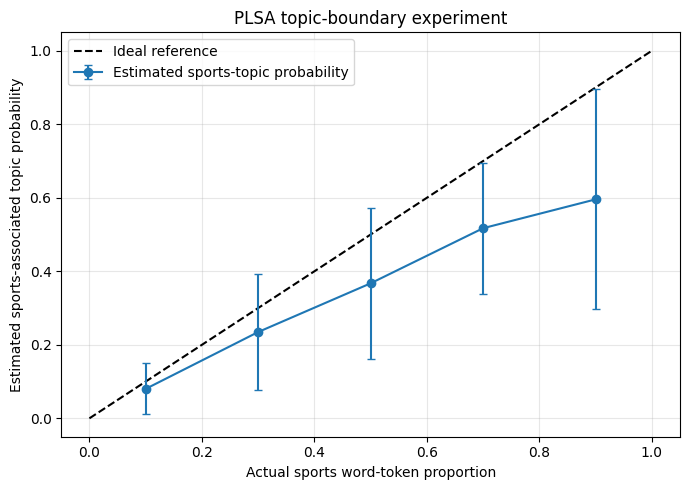

In [12]:
plt.figure(figsize=(7, 5))
plt.plot([0, 1], [0, 1], "k--", label="Ideal reference")
plt.errorbar(
    boundary_summary["actual_sports_word_ratio"],
    boundary_summary["estimated_sports_mean"],
    yerr=boundary_summary["estimated_sports_std"],
    marker="o", capsize=3, label="Estimated sports-topic probability"
)
plt.xlabel("Actual sports word-token proportion")
plt.ylabel("Estimated sports-associated topic probability")
plt.title("PLSA topic-boundary experiment")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 9. TF-IDF and LSI baselines

All baseline models are trained using only the training documents. LSI converts TF-IDF data into a smaller set of features using SVD. Unlike PLSA, which represents topics using probabilities, LSI represents documents using numerical values in a lower-dimensional space.

In [13]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=False, tokenizer=str.split, token_pattern=None,
    max_features=3000, min_df=3, max_df=0.90
)
X_train_tfidf = tfidf_vectorizer.fit_transform(docs_train_processed)
X_val_tfidf = tfidf_vectorizer.transform(docs_val_processed)
X_test_tfidf = tfidf_vectorizer.transform(docs_test_processed)
n_components = min(50, X_train_tfidf.shape[0]-1, X_train_tfidf.shape[1]-1)
lsi_model = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    Normalizer(copy=False)
)
lsi_train = lsi_model.fit_transform(X_train_tfidf)
lsi_val = lsi_model.transform(X_val_tfidf)
lsi_test = lsi_model.transform(X_test_tfidf)
print("TF-IDF train/validation/test:", X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)
print("LSI train/validation/test:", lsi_train.shape, lsi_val.shape, lsi_test.shape)


TF-IDF train/validation/test: (3497, 3000) (1166, 3000) (1166, 3000)
LSI train/validation/test: (3497, 50) (1166, 50) (1166, 50)


## 10. Validation-driven retrieval evaluation

Each category has three types of queries: direct keywords, rephrased queries, and related terms. We use category labels to identify relevant documents. The validation set helps us choose the best PLSA settings using AP@10. Once the settings are fixed, we evaluate performance on the test set. All methods use the same queries and documents for a fair comparison.


In [14]:
query_bank = {
    "comp.graphics": [("direct", "computer graphics rendering image pixels"), ("paraphrase", "raster visualization color drawing display"), ("related_terms", "jpeg gif image resolution file format")],
    "misc.forsale": [("direct", "for sale price shipping offer"), ("paraphrase", "selling item cost postage interested"), ("related_terms", "available purchase asking price contact")],
    "rec.sport.baseball": [("direct", "baseball players team season game"), ("paraphrase", "pitcher batter inning home run"), ("related_terms", "major league baseball statistics runs")],
    "sci.med": [("direct", "medical doctor disease treatment health"), ("paraphrase", "patient symptom diagnosis medication clinical"), ("related_terms", "hospital therapy drug research study")],
    "sci.space": [("direct", "space NASA spacecraft orbit planet"), ("paraphrase", "shuttle mission satellite launch moon"), ("related_terms", "astronomy universe planetary exploration")],
    "talk.politics.guns": [("direct", "gun control firearms second amendment"), ("paraphrase", "weapon legislation rights handgun rifle"), ("related_terms", "firearm policy congress law")],
}
assert set(query_bank) == set(target_names)
K_GRID, BACKGROUND_GRID, N_RESTARTS, TOP_K = [3, 6, 10, 20], [0.0, 0.01, 0.05], 3, 10
background_probability = np.asarray(X_train.sum(axis=0)).ravel().astype(float)
background_probability /= background_probability.sum()

def metrics_at_k(scores, labels, target, k=TOP_K):
    order = np.argsort(np.asarray(scores))[::-1]
    relevant = (np.asarray(labels) == target).astype(int)
    total = int(relevant.sum())
    selected = relevant[order[:k]]
    precision = float(selected.sum() / min(k, len(relevant)))
    recall = float(selected.sum() / total) if total else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    ranks = np.flatnonzero(selected) + 1
    ap = float(sum((i + 1) / rank for i, rank in enumerate(ranks)) / min(total, k)) if total else 0.0
    mrr = float(1 / ranks[0]) if len(ranks) else 0.0
    return {"Precision@10": precision, "Recall@10": recall, "F1@10": f1, "AP@10": ap, "MRR": mrr}

def evaluate_split(model, theta_docs, split_name, labels, processed_docs,
                   tfidf_docs, lsi_docs, bg_weight=0.0):
    eligible = np.asarray([bool(x.strip()) for x in processed_docs])
    y_eval, theta = np.asarray(labels)[eligible], theta_docs[eligible]
    tfidf_eval, lsi_eval = tfidf_docs[eligible], lsi_docs[eligible]
    rows = []
    for category, variants in query_bank.items():
        target = target_names.index(category)
        for query_type, query_text in variants:
            query = preprocess_texts([query_text])[0]
            q_count = count_vectorizer.transform([query]).astype(np.float64)
            q_tfidf = tfidf_vectorizer.transform([query])
            q_lsi = lsi_model.transform(q_tfidf)
            q_theta = model.fold_in(q_count, max_iter=100)
            scores = {
                "TF-IDF/VSM": cosine_similarity(q_tfidf, tfidf_eval).ravel(),
                "LSI": cosine_similarity(q_lsi, lsi_eval).ravel(),
                "PLSA cosine": cosine_similarity(q_theta, theta).ravel(),
            }
            likelihood = np.zeros(len(y_eval), dtype=float)
            q_csr = csr_matrix(q_count)
            for word_id, count in zip(q_csr.indices, q_csr.data):
                p_doc = theta @ model.phi_[:, word_id]
                p_word = (1 - bg_weight) * p_doc + bg_weight * background_probability[word_id]
                likelihood += count * np.log(np.maximum(p_word, 1e-12))
            scores["PLSA query likelihood"] = likelihood
            for method, ranking_scores in scores.items():
                rows.append({"split": split_name, "query_category": category,
                             "query_type": query_type, "query_text": query_text,
                             "method": method, "background_weight": bg_weight,
                             **metrics_at_k(ranking_scores, y_eval, target)})
    return rows


likelihood_choices, cosine_choices, models = [], [], {}
for k_topics in K_GRID:
    model, _ = train_plsa_restarts(
        X_train, n_topics=k_topics, n_restarts=N_RESTARTS,
        max_iter=100, base_seed=SEED + 100 * k_topics
    )
    models[k_topics] = model
    theta_val_candidate = model.fold_in(X_val, max_iter=100)
    for weight in BACKGROUND_GRID:
        rows = evaluate_split(model, theta_val_candidate, "validation", y_val,
                              docs_val_processed, X_val_tfidf, lsi_val, weight)
        ll = [r for r in rows if r["method"] == "PLSA query likelihood"]
        likelihood_choices.append({"K": k_topics, "background_weight": weight,
                                   "MAP@10": np.mean([r["AP@10"] for r in ll]),
                                   "Precision@10": np.mean([r["Precision@10"] for r in ll])})
        if weight == 0:
            cos = [r for r in rows if r["method"] == "PLSA cosine"]
            cosine_choices.append({"K": k_topics,
                                   "MAP@10": np.mean([r["AP@10"] for r in cos]),
                                   "Precision@10": np.mean([r["Precision@10"] for r in cos])})

likelihood_tuning = pd.DataFrame(likelihood_choices)
cosine_tuning = pd.DataFrame(cosine_choices)
display(likelihood_tuning.sort_values(["MAP@10", "Precision@10"], ascending=False))
display(cosine_tuning.sort_values(["MAP@10", "Precision@10"], ascending=False))
best_ll = max(likelihood_choices, key=lambda r: (r["MAP@10"], r["Precision@10"], -r["K"], -r["background_weight"]))
best_cos = max(cosine_choices, key=lambda r: (r["MAP@10"], r["Precision@10"], -r["K"]))
ll_model, cos_model = models[best_ll["K"]], models[best_cos["K"]]
print("Validation-selected PLSA query likelihood:", best_ll)
print("Validation-selected PLSA cosine:", best_cos)


theta_test_ll = ll_model.fold_in(X_test, max_iter=100)
theta_test_cos = cos_model.fold_in(X_test, max_iter=100)
evaluation_rows = []
eligible = np.asarray([bool(x.strip()) for x in docs_test_processed])
y_test_eval = np.asarray(y_test)[eligible]
for category, variants in query_bank.items():
    target = target_names.index(category)
    for query_type, query_text in variants:
        query = preprocess_texts([query_text])[0]
        q_count = count_vectorizer.transform([query]).astype(np.float64)
        q_tfidf = tfidf_vectorizer.transform([query])
        q_lsi = lsi_model.transform(q_tfidf)
        q_cos = cos_model.fold_in(q_count, max_iter=100)
        scores = {
            "TF-IDF/VSM": cosine_similarity(q_tfidf, X_test_tfidf[eligible]).ravel(),
            "LSI": cosine_similarity(q_lsi, lsi_test[eligible]).ravel(),
            "PLSA cosine": cosine_similarity(q_cos, theta_test_cos[eligible]).ravel(),
        }
        likelihood = np.zeros(int(eligible.sum()), dtype=float)
        q_csr = csr_matrix(q_count)
        for word_id, count in zip(q_csr.indices, q_csr.data):
            p_doc = theta_test_ll[eligible] @ ll_model.phi_[:, word_id]
            p_word = (1 - best_ll["background_weight"]) * p_doc + best_ll["background_weight"] * background_probability[word_id]
            likelihood += count * np.log(np.maximum(p_word, 1e-12))
        scores["PLSA query likelihood"] = likelihood
        for method, ranking_scores in scores.items():
            evaluation_rows.append({"split": "test", "query_category": category,
                                    "query_type": query_type, "query_text": query_text,
                                    "method": method,
                                    **metrics_at_k(ranking_scores, y_test_eval, target)})

evaluation_df = pd.DataFrame(evaluation_rows)
print("Final held-out test results by method:")
display(evaluation_df.groupby("method")[["Precision@10", "Recall@10", "F1@10", "AP@10", "MRR"]].mean())
print("Test results by query family:")
display(evaluation_df.groupby(["query_type", "method"])[["Precision@10", "AP@10", "MRR"]].mean())


Restart 1: final training log-likelihood=-1429107.418, iterations=32
Restart 2: final training log-likelihood=-1432746.602, iterations=32
Restart 3: final training log-likelihood=-1433146.266, iterations=51
Selected best training likelihood: -1429107.418
Restart 1: final training log-likelihood=-1387882.144, iterations=55
Restart 2: final training log-likelihood=-1381371.854, iterations=47
Restart 3: final training log-likelihood=-1383227.339, iterations=37
Selected best training likelihood: -1381371.854
Restart 1: final training log-likelihood=-1353638.559, iterations=68
Restart 2: final training log-likelihood=-1350923.000, iterations=70
Restart 3: final training log-likelihood=-1355436.698, iterations=62
Selected best training likelihood: -1350923.0
Restart 1: final training log-likelihood=-1312280.380, iterations=58
Restart 2: final training log-likelihood=-1312378.181, iterations=69
Restart 3: final training log-likelihood=-1313111.301, iterations=57
Selected best training likelih

,K,background_weight,MAP@10,Precision@10
9,20,0.00,0.950375,0.977778
10,20,0.01,0.950375,0.977778
11,20,0.05,0.950375,0.977778
3,6,0.00,0.892163,0.950000
4,6,0.01,0.892163,0.950000
5,6,0.05,0.892163,0.950000
6,10,0.00,0.851184,0.916667
7,10,0.01,0.851184,0.916667
8,10,0.05,0.851184,0.916667
0,3,0.00,0.317436,0.455556


,K,MAP@10,Precision@10
3,20,0.986506,0.994444
2,10,0.775774,0.877778
1,6,0.726133,0.811111
0,3,0.287857,0.450000


Validation-selected PLSA query likelihood: {'K': 20, 'background_weight': 0.0, 'MAP@10': np.float64(0.9503747795414463), 'Precision@10': np.float64(0.9777777777777776)}
Validation-selected PLSA cosine: {'K': 20, 'MAP@10': np.float64(0.9865057319223985), 'Precision@10': np.float64(0.9944444444444444)}
Final held-out test results by method:


,Precision@10,Recall@10,F1@10,AP@10,MRR
method,,,,,
LSI,0.961111,0.050924,0.096718,0.933468,0.972222
PLSA cosine,0.966667,0.051211,0.097265,0.920608,0.972222
PLSA query likelihood,0.955556,0.050633,0.096165,0.926140,0.944444
TF-IDF/VSM,0.894444,0.047400,0.090025,0.836618,0.972222


Test results by query family:


Precision@10     AP@10       MRR
query_type    method                                                 
direct        LSI                        1.000000  1.000000  1.000000
              PLSA cosine                0.966667  0.932090  1.000000
              PLSA query likelihood      0.950000  0.909868  0.916667
              TF-IDF/VSM                 0.983333  0.975351  1.000000
paraphrase    LSI                        0.916667  0.865886  1.000000
              PLSA cosine                0.950000  0.870218  0.916667
              PLSA query likelihood      0.950000  0.909868  0.916667
              TF-IDF/VSM                 0.900000  0.859444  0.916667
related_terms LSI                        0.966667  0.934517  0.916667
              PLSA cosine                0.983333  0.959517  1.000000
              PLSA query likelihood      0.966667  0.958684  1.000000
              TF-IDF/VSM                 0.800000  0.675060  1.000000

## 11. PLSA Inference: Runtime and Memory Profiling

After training, we use both the cosine-based and query-likelihood PLSA models to estimate topic distributions for test documents. We measure the time taken and memory used by each method, with a maximum of 100 iterations for inference. This helps us compare their computational efficiency and understand the resources needed to process unseen documents.

In [15]:
_, cosine_inference_measurements = profile_resources(
    cos_model.fold_in, X_test, max_iter=100
)

_, likelihood_inference_measurements = profile_resources(
    ll_model.fold_in, X_test, max_iter=100
)

inference_resources_df = pd.DataFrame([
    {
        "operation": "Cosine model: infer test topic mixtures",
        "K": cos_model.n_topics,
        **cosine_inference_measurements
    },
    {
        "operation": "Query-likelihood model: infer test topic mixtures",
        "K": ll_model.n_topics,
        **likelihood_inference_measurements
    }
])

display(inference_resources_df)

,operation,K,runtime_seconds,memory_before_MB,memory_after_MB,peak_process_memory_MB,peak_increase_from_start_MB
0,Cosine model: infer test topic mixtures,20,7.728,129.70,132.66,132.79,3.09
1,Query-likelihood model: infer test topic mixtures,20,7.716,132.78,133.16,133.17,0.39


## 12. Query Vocabulary Coverage and Retrieval Analysis

This experiment checks how many words in each query are present in the training vocabulary and how well each retrieval method performs on individual queries. It also compares AP@10 for related-term queries across categories to understand how effectively the models retrieve relevant documents when queries use different words from those in the documents.

In [16]:

vocabulary = set(count_vectorizer.vocabulary_)
coverage_rows = []
for category, variants in query_bank.items():
    for query_type, query_text in variants:
        processed = preprocess_texts([query_text])[0]
        tokens = processed.split()
        unique_tokens = set(tokens)
        matched = unique_tokens & vocabulary
        coverage_rows.append({
            "query_category": category,
            "query_type": query_type,
            "query_text": query_text,
            "preprocessed_query": processed,
            "unique_query_terms": len(unique_tokens),
            "terms_in_training_vocabulary": len(matched),
            "terms_oov": len(unique_tokens - vocabulary),
            "vocabulary_coverage": len(matched) / len(unique_tokens) if unique_tokens else 0.0,
        })

query_coverage_df = pd.DataFrame(coverage_rows)
print("Query coverage against the training vocabulary:")
display(query_coverage_df.sort_values(["query_category", "query_type"]))

per_query_results = evaluation_df.merge(
    query_coverage_df[
        ["query_category", "query_type", "query_text",
         "unique_query_terms", "terms_in_training_vocabulary",
         "terms_oov", "vocabulary_coverage"]
    ],
    on=["query_category", "query_type", "query_text"],
    how="left",
    validate="many_to_one",
)
print("Held-out test metrics for each query and method:")
display(per_query_results.sort_values(
    ["query_category", "query_type", "method"]
)[[
    "query_category", "query_type", "query_text", "method",
    "vocabulary_coverage", "Precision@10", "AP@10", "MRR"
]])

print("Related-terms AP@10 by category and method:")
display(per_query_results[per_query_results["query_type"] == "related_terms"].pivot(
    index="query_category", columns="method", values="AP@10"
))


Query coverage against the training vocabulary:


,query_category,query_type,query_text,preprocessed_query,unique_query_terms,terms_in_training_vocabulary,terms_oov,vocabulary_coverage
0,comp.graphics,direct,computer graphics rendering image pixels,computer graphic render image pixel,5,5,0,1.0
1,comp.graphics,paraphrase,raster visualization color drawing display,raster visualization color drawing display,5,5,0,1.0
2,comp.graphics,related_terms,jpeg gif image resolution file format,jpeg gif image resolution file format,6,6,0,1.0
3,misc.forsale,direct,for sale price shipping offer,sale price shipping offer,4,4,0,1.0
4,misc.forsale,paraphrase,selling item cost postage interested,sell item cost postage interested,5,5,0,1.0
5,misc.forsale,related_terms,available purchase asking price contact,available purchase ask price contact,5,5,0,1.0
6,rec.sport.baseball,direct,baseball players team season game,baseball player team season game,5,5,0,1.0
7,rec.sport.baseball,paraphrase,pitcher batter inning home run,pitcher batter inne home run,5,4,1,0.8
8,rec.sport.baseball,related_terms,major league baseball statistics runs,major league baseball statistic run,5,5,0,1.0
9,sci.med,direct,medical doctor disease treatment health,medical doctor disease treatment health,5,5,0,1.0


Held-out test metrics for each query and method:


,query_category,query_type,query_text,method,vocabulary_coverage,Precision@10,AP@10,MRR
1,comp.graphics,direct,computer graphics rendering image pixels,LSI,1.0,1.0,1.000000,1.0
2,comp.graphics,direct,computer graphics rendering image pixels,PLSA cosine,1.0,1.0,1.000000,1.0
3,comp.graphics,direct,computer graphics rendering image pixels,PLSA query likelihood,1.0,1.0,1.000000,1.0
0,comp.graphics,direct,computer graphics rendering image pixels,TF-IDF/VSM,1.0,1.0,1.000000,1.0
5,comp.graphics,paraphrase,raster visualization color drawing display,LSI,1.0,0.9,0.790437,1.0
...,...,...,...,...,...,...,...,...
64,talk.politics.guns,paraphrase,weapon legislation rights handgun rifle,TF-IDF/VSM,1.0,0.8,0.788889,1.0
69,talk.politics.guns,related_terms,firearm policy congress law,LSI,1.0,0.9,0.707103,0.5
70,talk.politics.guns,related_terms,firearm policy congress law,PLSA cosine,1.0,1.0,1.000000,1.0
71,talk.politics.guns,related_terms,firearm policy congress law,PLSA query likelihood,1.0,1.0,1.000000,1.0


Related-terms AP@10 by category and method:


method,LSI,PLSA cosine,PLSA query likelihood,TF-IDF/VSM
query_category,,,,
comp.graphics,1.000000,1.000000,1.000000,1.000000
misc.forsale,0.900000,1.000000,1.000000,0.365556
rec.sport.baseball,1.000000,0.757103,0.852103,0.815437
sci.med,1.000000,1.000000,0.900000,0.671111
sci.space,1.000000,1.000000,1.000000,0.549762
talk.politics.guns,0.707103,1.000000,1.000000,0.648492


## 13. Retrieval Performance by Query Type

We compare PLSA, TF-IDF, and LSI across direct queries, paraphrases, and related-term queries. We also compare AP@10 for each query to identify where PLSA performs better or worse than the baseline methods.

In [17]:
# Average retrieval performance by query family and method

query_family_summary = (
    evaluation_df
    .groupby(["query_type", "method"])[
        ["Precision@10", "Recall@10", "F1@10", "AP@10", "MRR"]
    ]
    .mean()
    .reset_index()
)

display(
    query_family_summary.sort_values(
        ["query_type", "AP@10"],
        ascending=[True, False]
    )
)

# Compare PLSA cosine with TF-IDF and LSI for each individual query

query_comparison = evaluation_df.pivot_table(
    index=["query_category", "query_type", "query_text"],
    columns="method",
    values="AP@10",
    aggfunc="first"
).reset_index()

query_comparison["PLSA_cosine_minus_TFIDF"] = (
    query_comparison["PLSA cosine"]
    - query_comparison["TF-IDF/VSM"]
)

query_comparison["PLSA_cosine_minus_LSI"] = (
    query_comparison["PLSA cosine"]
    - query_comparison["LSI"]
)

display(
    query_comparison.sort_values(
        "PLSA_cosine_minus_TFIDF",
        ascending=False
    )
)

,query_type,method,Precision@10,Recall@10,F1@10,AP@10,MRR
0,direct,LSI,1.000000,0.053009,0.100677,1.000000,1.000000
3,direct,TF-IDF/VSM,0.983333,0.052141,0.099026,0.975351,1.000000
1,direct,PLSA cosine,0.966667,0.051185,0.097218,0.932090,1.000000
2,direct,PLSA query likelihood,0.950000,0.050317,0.095568,0.909868,0.916667
6,paraphrase,PLSA query likelihood,0.950000,0.050317,0.095568,0.909868,0.916667
5,paraphrase,PLSA cosine,0.950000,0.050317,0.095568,0.870218,0.916667
4,paraphrase,LSI,0.916667,0.048567,0.092243,0.865886,1.000000
7,paraphrase,TF-IDF/VSM,0.900000,0.047634,0.090475,0.859444,0.916667
9,related_terms,PLSA cosine,0.983333,0.052132,0.099010,0.959517,1.000000
10,related_terms,PLSA query likelihood,0.966667,0.051264,0.097360,0.958684,1.000000


method,query_category,query_type,query_text,LSI,PLSA cosine,PLSA query likelihood,TF-IDF/VSM,PLSA_cosine_minus_TFIDF,PLSA_cosine_minus_LSI
5,misc.forsale,related_terms,available purchase asking price contact,0.900000,1.000000,1.000000,0.365556,0.634444,0.100000
14,sci.space,related_terms,astronomy universe planetary exploration,1.000000,1.000000,1.000000,0.549762,0.450238,0.000000
4,misc.forsale,paraphrase,selling item cost postage interested,0.890000,1.000000,1.000000,0.587778,0.412222,0.110000
17,talk.politics.guns,related_terms,firearm policy congress law,0.707103,1.000000,1.000000,0.648492,0.351508,0.292897
11,sci.med,related_terms,hospital therapy drug research study,1.000000,1.000000,0.900000,0.671111,0.328889,0.000000
1,comp.graphics,paraphrase,raster visualization color drawing display,0.790437,1.000000,1.000000,0.780000,0.220000,0.209563
3,misc.forsale,direct,for sale price shipping offer,1.000000,1.000000,1.000000,0.852103,0.147897,0.000000
0,comp.graphics,direct,computer graphics rendering image pixels,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
9,sci.med,direct,medical doctor disease treatment health,1.000000,1.000000,0.900000,1.000000,0.000000,0.000000
2,comp.graphics,related_terms,jpeg gif image resolution file format,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000


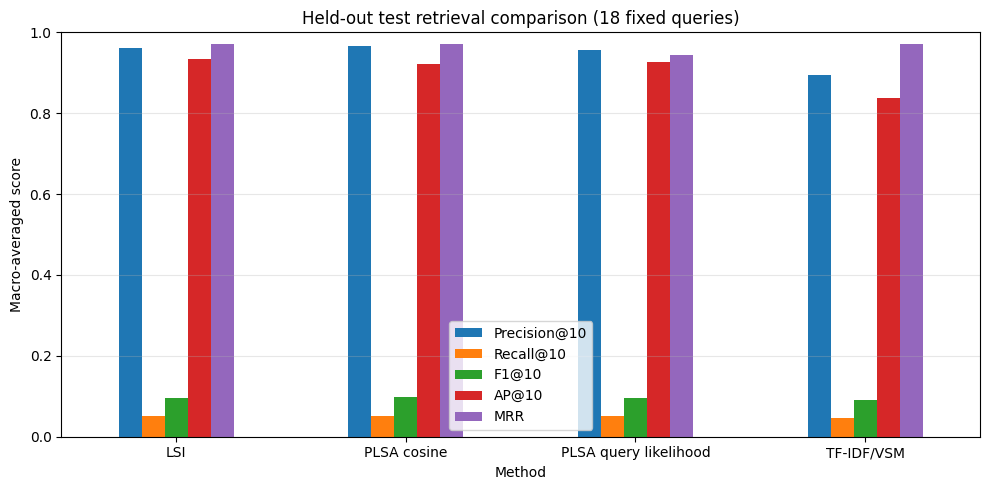

In [18]:
test_summary = evaluation_df.groupby("method")[["Precision@10", "Recall@10", "F1@10", "AP@10", "MRR"]].mean()
test_summary.plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
plt.title("Held-out test retrieval comparison (18 fixed queries)")
plt.ylabel("Macro-averaged score")
plt.xlabel("Method")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 14. Model-order study: how does K affect the model?

Compare different values of K on the same six-category training set to see how the number of topics affects training convergence and topic separation. We record the training log-likelihood and the number of iterations required for convergence. However, a higher training likelihood does not necessarily mean better retrieval performance on unseen documents.

In [19]:
k_rows = []
for k_topics in [2, 3, 5, 6, 8, 10, 20]:
    model = PLSA(
        n_topics=k_topics, max_iter=80, tol=1e-4,
        random_state=SEED, beta=1.0
    ).fit(X_train)
    k_rows.append({
        "K": k_topics,
        "iterations": model.n_iter_,
        "train_log_likelihood": model.log_likelihoods[-1],
        "test_documents": X_test.shape[0]
    })

k_df = pd.DataFrame(k_rows)
display(k_df)


,K,iterations,train_log_likelihood,test_documents
0,2,21,-1.449535e+06,1166
1,3,40,-1.428309e+06,1166
2,5,52,-1.398368e+06,1166
3,6,44,-1.389493e+06,1166
4,8,50,-1.374230e+06,1166
5,10,53,-1.349770e+06,1166
6,20,60,-1.315410e+06,1166


In [21]:
training_resources_df.to_csv(
    "plsa_training_resources.csv", index=False
)

inference_resources_df.to_csv(
    "plsa_inference_resources.csv", index=False
)

per_query_results.to_csv(
    "plsa_per_query_test_results.csv", index=False
)

query_family_summary.to_csv(
    "plsa_query_family_summary.csv", index=False
)

query_comparison.to_csv(
    "plsa_query_comparison.csv", index=False
)

print("All five CSV files have been saved.")

All five CSV files have been saved.


## 15. Limitations

1. We use only six categories from the 20 Newsgroups dataset, so the results may be different when tested on all 20 categories.
2. PLSA learns topics without using category labels during training. The labels are used only for splitting the data, selecting documents for experiments, and evaluating retrieval.
3. The topics learned by PLSA may not match the six categories exactly. One category may be split into multiple topics, or similar categories may share a topic.
4. In the mixture experiment, the proportion of baseball and gun-politics words may not exactly match the topic probabilities estimated by PLSA.
5. A model with a higher training log-likelihood does not necessarily perform better when retrieving unseen documents.
6. Our evaluation uses a small, fixed set of queries, and category labels serve as an approximate measure of relevance. Human evaluation of query results could provide a more reliable assessment.
7. Memory and runtime profiling helps us understand the resources required for training and retrieval, but the measurements depend on the machine and environment used. They may differ on other systems or with larger datasets.